## 2.0 K-Means Clustering

In [1]:
# Imports necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import hashlib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import silhouette_score


# Generate seed based on my college ID.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)

# Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="rocket", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.tight_layout()
    plt.show()

def coordplot(ax, title, x_label, y_label):
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)


# Loaded and Preprocessed the Data.
df = pd.read_csv("data/clustering_dataset.csv")

missing_count = df['Genre'].isnull().sum()
choices = ['Male', 'Female']
random_genres = rng.choice(choices, size=missing_count)
df.loc[df['Genre'].isnull(), 'Genre'] = random_genres

numerical_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

genre_dummies = pd.get_dummies(df['Genre'], prefix='Genre')
df_processed = pd.concat([df.drop('Genre', axis=1), genre_dummies], axis=1)

Seed generated: 1027714457


### 2.1 Implement a K-Means Class

In [2]:
class KMeansClustering:
    def __init__(self, k=3, max_iter=100, random_state=42):
        self.k = k
        self.max_iter = max_iter
        self.random_state = random_state
        self.centroids = None

    def fit(self, X):
        # Set a seed for reproducible centroid initialization
        np.random.seed(self.random_state)
        
        # 1. Initialize centroids by randomly selecting k points from the data
        n_samples, n_features = X.shape
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids = X[random_indices]

        for _ in range(self.max_iter):
            # 2. Assign clusters: Create a list of k empty lists
            clusters = [[] for _ in range(self.k)]
            for idx, sample in enumerate(X):
                # Find the closest centroid to the current sample with Euclidean distance.
                distances = [np.sqrt(np.sum((sample - point)**2)) for point in self.centroids]
                closest_centroid_idx = np.argmin(distances)
                clusters[closest_centroid_idx].append(idx)
            
            # Store old centroids to check for convergence
            old_centroids = self.centroids
            
            # 3. Update centroids: Calculate the mean of the points in each cluster
            new_centroids = np.zeros((self.k, n_features))
            for cluster_idx, cluster_points in enumerate(clusters):
                if cluster_points: # Avoid empty clusters
                    cluster_mean = np.mean(X[cluster_points], axis=0)
                    new_centroids[cluster_idx] = cluster_mean
            
            self.centroids = new_centroids
            
            # 4. Check for convergence: If centroids don't change, we're done
            distances = [np.sqrt(np.sum((old_centroids[i] - self.centroids[i])**2)) for i in range(self.k)]
            if sum(distances) == 0:
                break

    def predict(self, X):
        if self.centroids is None:
            raise Exception("Model has not been fitted yet. Please call fit() first.")
            
        cluster_labels = []
        for sample in X:
            distances = [np.sqrt(np.sum((sample - point)**2)) for point in self.centroids]
            closest_centroid_idx = np.argmin(distances)
            cluster_labels.append(closest_centroid_idx)
            
        return np.array(cluster_labels)
    
    
    def getCost(self, X):
        if self.centroids is None:
            raise Exception("Model has not been fitted yet. Please call fit() first.")
            
        cost = 0
        # Get the cluster label for each data point
        labels = self.predict(X)
        
        # Iterate through each cluster
        for i in range(self.k):
            # Get all points belonging to the current cluster
            cluster_points = X[labels == i]
            
            # If the cluster is not empty, calculate the sum of squared distances
            if len(cluster_points) > 0:
                centroid = self.centroids[i]
                # Sum the squared Euclidean distance from each point to the centroid
                cost += np.sum((cluster_points - centroid)**2)
                
        return cost

The dataset's features are prepared & preprocessed by ***randomly assigning gender*** and ***assigning median*** of the current feature to missing numerical feature values.

Keep in mind that since there is a negligible number of missing values *(6)*, randomly assigning Gender to fill absent values does not skew the proportion heavily.

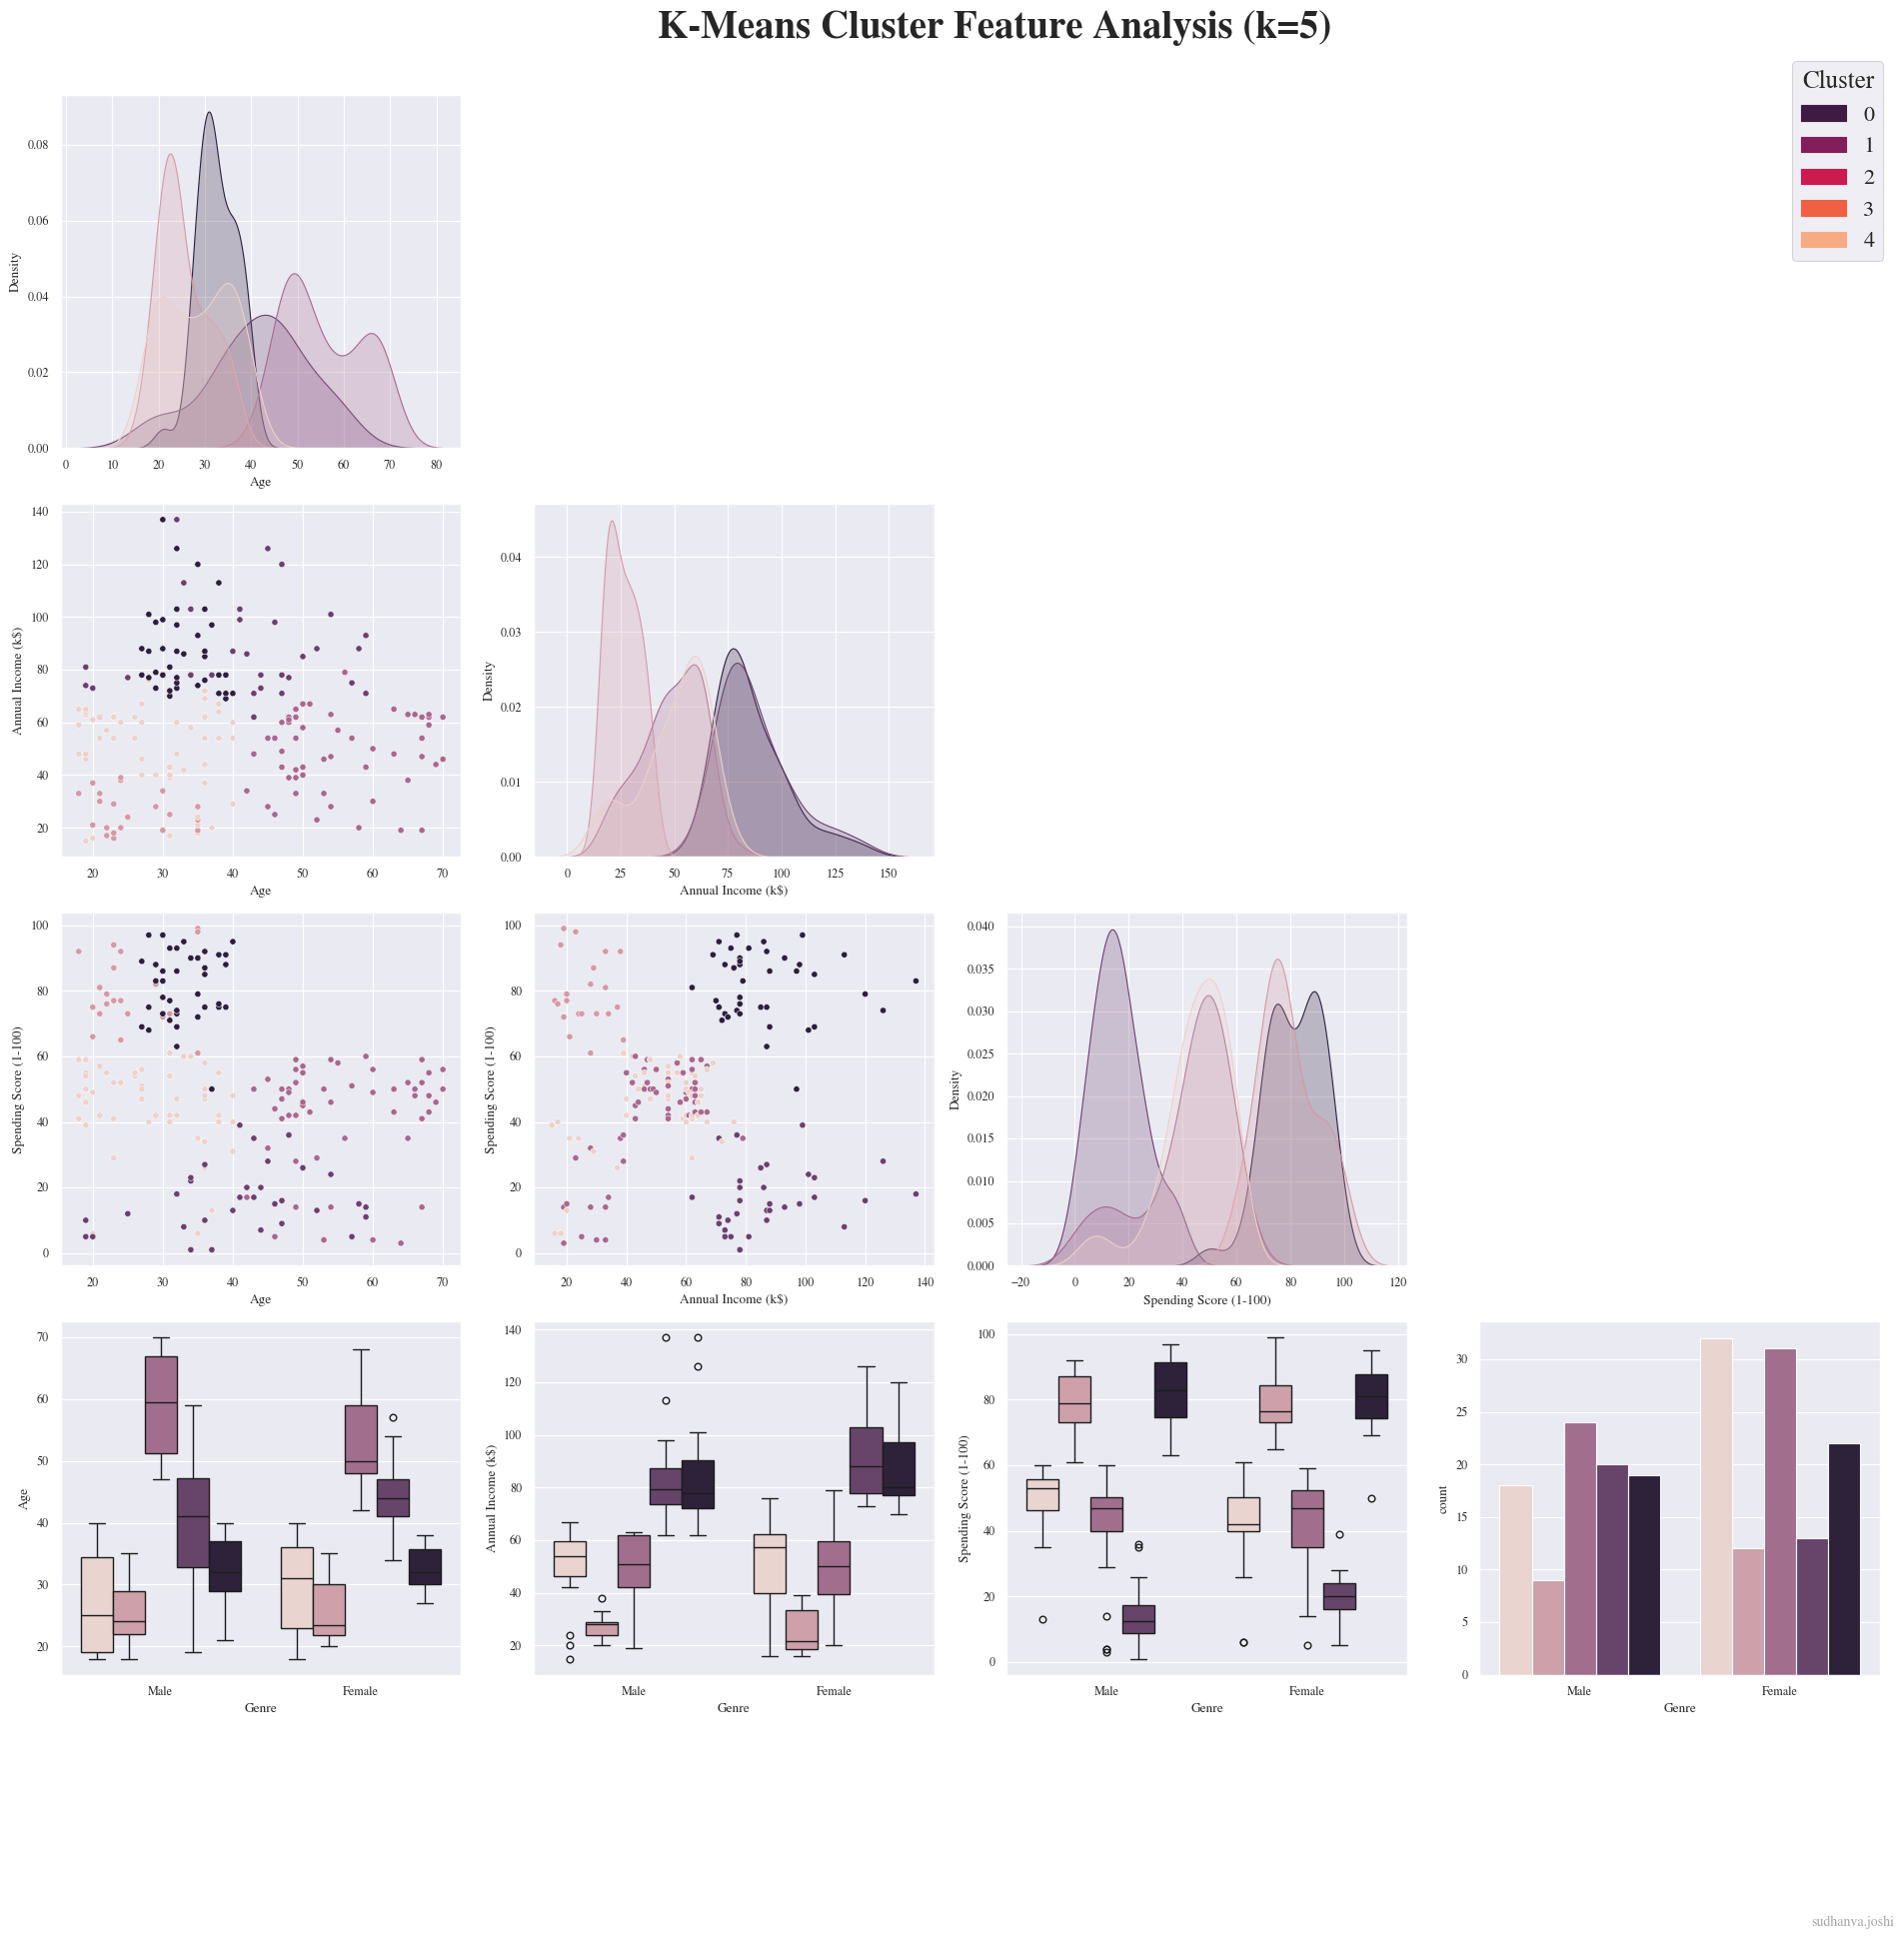

In [3]:
# --- Prepare Data for Clustering ---
scaler = StandardScaler()
numerical_features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
ohe_features = ['Genre_Female', 'Genre_Male']
X_scaled_numerical = scaler.fit_transform(df_processed[numerical_features])
X_ohe = df_processed[ohe_features].values
X_for_clustering = np.hstack([X_scaled_numerical, X_ohe])


# --- Run Final Clustering with Chosen K ---
k = 5
kmeans = KMeansClustering(k=k, random_state=seed)
kmeans.fit(X_for_clustering)
clusters = kmeans.predict(X_for_clustering)

# Now, create the DataFrame 'X' specifically for plotting purposes
X = df_processed[numerical_features].copy()
X['cluster'] = clusters
X['Genre'] = df['Genre']


# --- Generate the Custom Summary Plot ---
features_to_plot = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Genre']
categorical_features = ['Genre']
n_features = len(features_to_plot)
fig, axes = plt.subplots(nrows=n_features, ncols=n_features, figsize=(20, 20))

for i, row_var in enumerate(features_to_plot):
    for j, col_var in enumerate(features_to_plot):
        ax = axes[i, j]
        if i < j:
            ax.axis('off')
            continue
        if i == j:
            if row_var in categorical_features:
                sns.countplot(data=X, x=row_var, hue='cluster', ax=ax)
            else:
                sns.kdeplot(data=X, x=row_var, hue='cluster', ax=ax, fill=True, common_norm=False)
            if ax.get_legend():
                ax.get_legend().remove()
        else:
            row_is_cat = row_var in categorical_features
            col_is_cat = col_var in categorical_features
            if not row_is_cat and not col_is_cat:
                sns.scatterplot(data=X, x=col_var, y=row_var, hue='cluster', ax=ax, s=20)
                if ax.get_legend():
                    ax.get_legend().remove()
            else:
                if row_is_cat:
                    cat_var, num_var = row_var, col_var
                else:
                    cat_var, num_var = col_var, row_var
                sns.boxplot(data=X, x=cat_var, y=num_var, hue='cluster', ax=ax)
                if ax.get_legend():
                    ax.get_legend().remove()

# --- Final Touches ---
palette = sns.color_palette("rocket", n_colors=k)
handles = [mpatches.Patch(color=palette[i], label=str(i)) for i in range(k)]
labels = [str(i) for i in range(k)]
fig.legend(handles, labels, loc='upper right', title='Cluster', bbox_to_anchor=(0.95, 0.95), 
           fontsize=16, title_fontsize=18)
fig.suptitle(f"K-Means Cluster Feature Analysis (k={k})", fontsize=28, fontweight='bold', y=0.97)
plt.text(0.95, 0.01, username, ha="right", va="bottom",
         transform=plt.gcf().transFigure, fontsize=10, color="gray", alpha=0.7)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

### 2.2 Determine the Optimal Number of Clusters
Sweeping the k values for generating both Elbow and Silhouette Plots yields the following observations.

- ***Elbow Method:*** Although the plot is mostly linearly decreasing, potential k-values as elbow points include ***8, 10 & 12*** gives the optimal number of clusters.
 

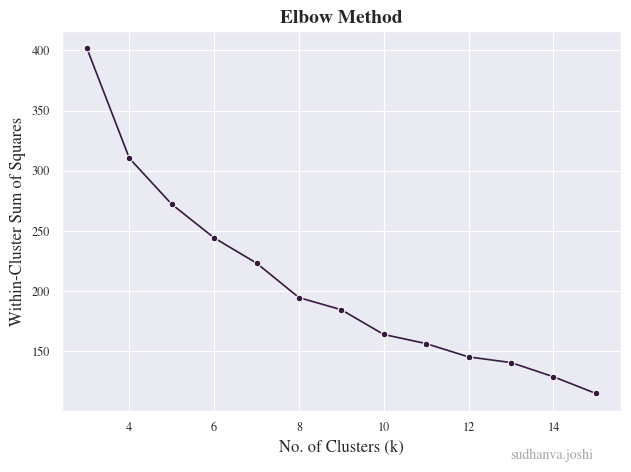

--- Cluster Profiles for k=8 (Elbow Method) ---
           Age  Annual Income (k$)  Spending Score (1-100)  Female  Male
cluster                                                                 
0        27.52               56.12                   49.30    0.62  0.38
1        25.18               25.73                   77.45    0.55  0.45
2        58.84               49.32                   39.64    0.00  1.00
3        40.80               25.93                   21.13    0.87  0.13
4        32.59               86.55                   80.23    1.00  0.00
5        40.84               88.28                   16.47    0.41  0.59
6        32.63               85.79                   82.58    0.00  1.00
7        53.92               55.12                   48.92    1.00  0.00


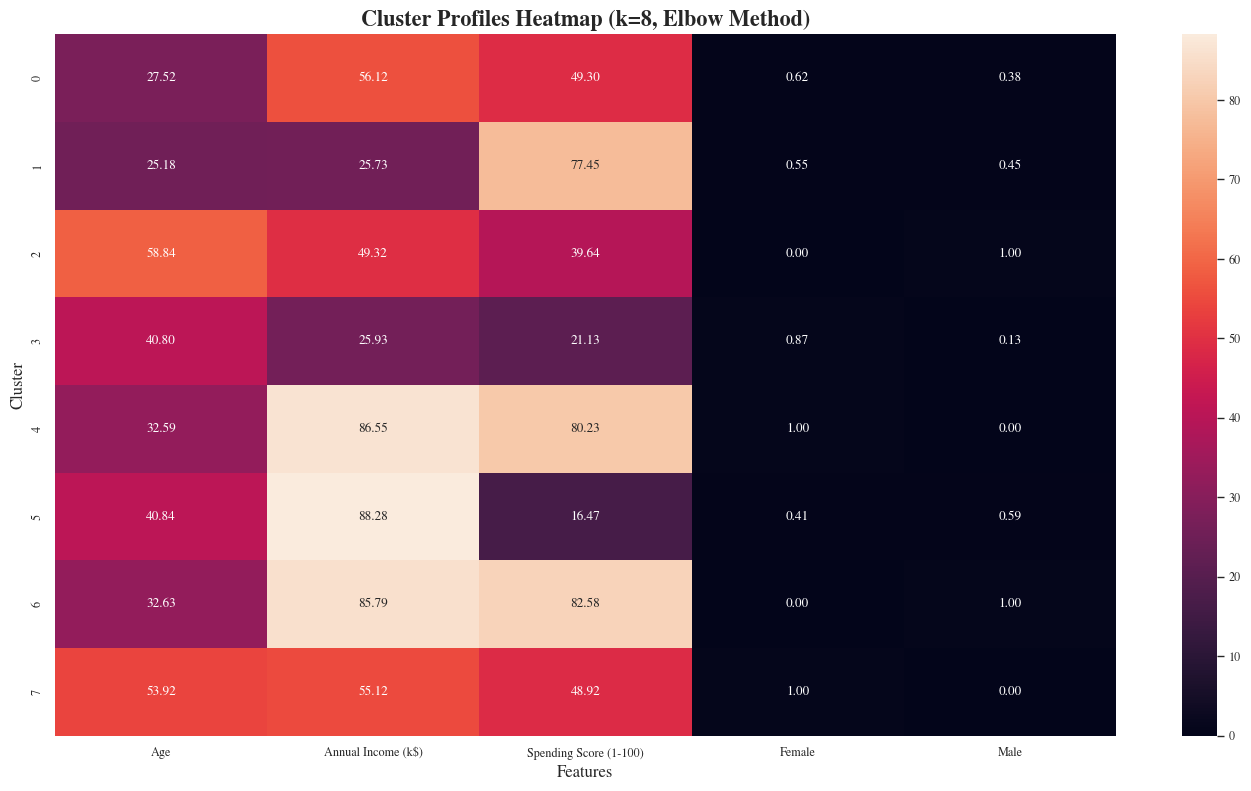

In [4]:
k_values = range(3, 16)
wcss_scores = []
silhouette_scores = []

for k_test in k_values:
    kmeans_test = KMeansClustering(k=k_test, random_state=seed)
    kmeans_test.fit(X_for_clustering)
    wcss_scores.append(kmeans_test.getCost(X_for_clustering))
    labels = kmeans_test.predict(X_for_clustering)
    silhouette_scores.append(silhouette_score(X_for_clustering, labels))

scores_df = pd.DataFrame({'k': k_values, 'WCSS': wcss_scores, 
                        'Silhouette Score': silhouette_scores})

sns.lineplot(data=scores_df, x='k', y='WCSS', marker='o')
plotinfo(title='Elbow Method', x='No. of Clusters (k)', 
         y='Within-Cluster Sum of Squares')

k_elbow = 8
kmeans_elbow = KMeansClustering(k=k_elbow, random_state=seed)
kmeans_elbow.fit(X_for_clustering)
clusters_elbow = kmeans_elbow.predict(X_for_clustering)

profiling_df_elbow = df.copy()
profiling_df_elbow['cluster'] = clusters_elbow
cluster_profile_elbow = profiling_df_elbow.groupby('cluster')[numerical_features].mean()
gender_distribution_elbow = profiling_df_elbow.groupby('cluster')['Genre'].value_counts(normalize=True).unstack().fillna(0)
full_profile_elbow = pd.concat([cluster_profile_elbow, gender_distribution_elbow], axis=1)

print(f"--- Cluster Profiles for k={k_elbow} (Elbow Method) ---")
print(full_profile_elbow.round(2))

plt.figure(figsize=(14, 8))
sns.heatmap(full_profile_elbow, annot=True, fmt='.2f')
plt.title(f'Cluster Profiles Heatmap (k={k_elbow}, Elbow Method)', fontsize=16, fontweight='bold')
plt.xlabel('Features', fontsize=12)
plt.ylabel('Cluster', fontsize=12)
plt.tight_layout()
plt.show()

- ***Silhouette Method:*** The optimal value in the plots is given as ***k=12***. The implications of these different clusters has been given in the heatmap generated below through a display of each feature's trend in the split.

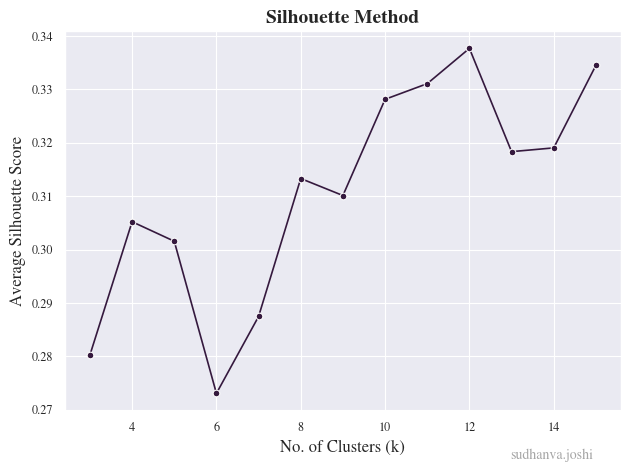

--- Cluster Profiles for k=12 (Silhouette Method) ---
           Age  Annual Income (k$)  Spending Score (1-100)  Female  Male
cluster                                                                 
0        27.78               55.41                   50.03    0.65  0.35
1        25.48               26.24                   79.29    0.57  0.43
2        58.74               54.63                   48.74    0.00  1.00
3        35.08               23.67                   23.75    0.75  0.25
4        32.38               86.05                   81.67    1.00  0.00
5        20.00               71.33                   19.83    0.00  1.00
6        33.12               79.12                   84.00    0.00  1.00
7        53.64               53.52                   48.64    1.00  0.00
8        45.00               83.00                   15.40    0.00  1.00
9        44.06               91.06                   23.50    1.00  0.00
10       30.50              125.25                   60.75    0.00  1.

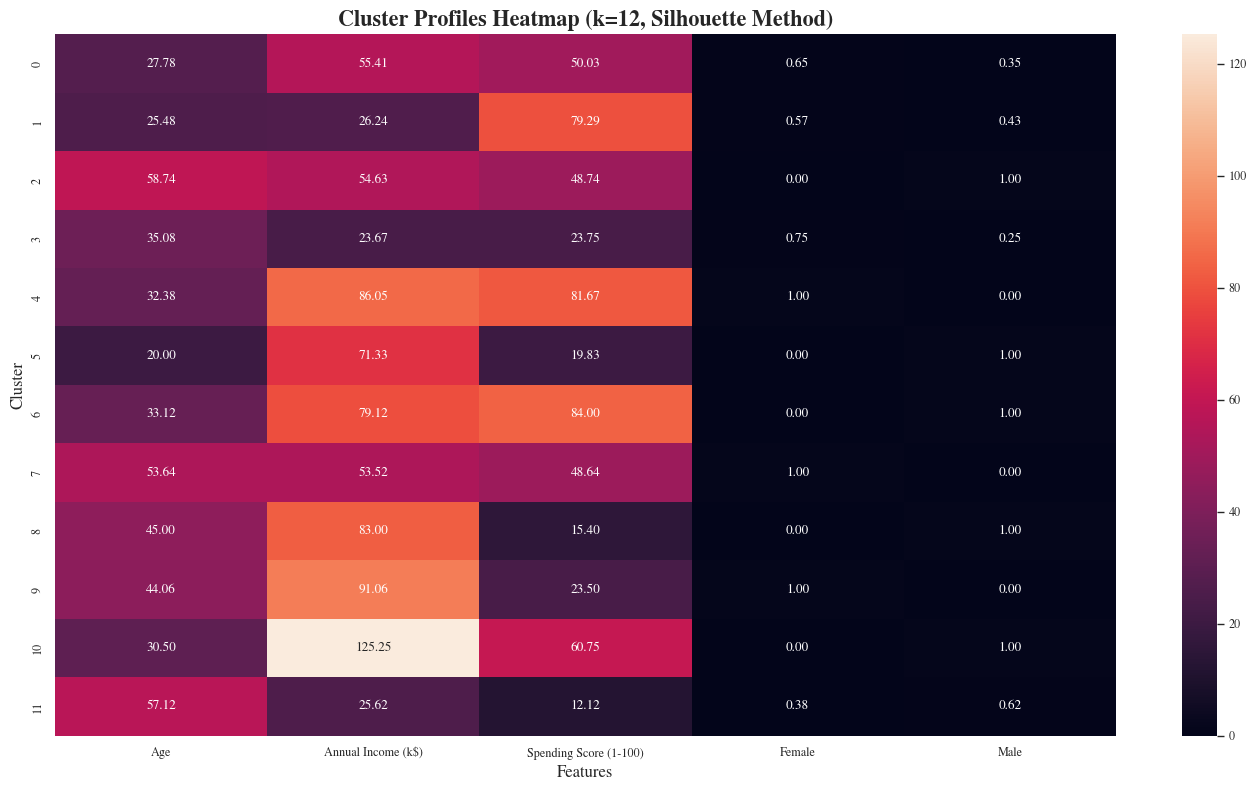

In [5]:
sns.lineplot(data=scores_df, x='k', y='Silhouette Score', marker='o')
plotinfo(title='Silhouette Method', x='No. of Clusters (k)', 
         y='Average Silhouette Score')

k_silhouette = 12
kmeans_silhouette = KMeansClustering(k=k_silhouette, random_state=seed)
kmeans_silhouette.fit(X_for_clustering)
clusters_silhouette = kmeans_silhouette.predict(X_for_clustering)

profiling_df_silhouette = df.copy()
profiling_df_silhouette['cluster'] = clusters_silhouette
cluster_profile_silhouette = profiling_df_silhouette.groupby('cluster')[numerical_features].mean()
gender_distribution_silhouette = profiling_df_silhouette.groupby('cluster')['Genre'].value_counts(normalize=True).unstack().fillna(0)
full_profile_silhouette = pd.concat([cluster_profile_silhouette, gender_distribution_silhouette], axis=1)

print(f"--- Cluster Profiles for k={k_silhouette} (Silhouette Method) ---")
print(full_profile_silhouette.round(2))

plt.figure(figsize=(14, 8))
sns.heatmap(full_profile_silhouette, annot=True, fmt='.2f')
plt.title(f'Cluster Profiles Heatmap (k={k_silhouette}, Silhouette Method)', fontsize=16, fontweight='bold')
plt.xlabel('Features', fontsize=12)
plt.ylabel('Cluster', fontsize=12)
plt.tight_layout()
plt.show()